<a href="https://colab.research.google.com/github/bgeethagayathri2-del/Flower-classifier-transfer-learning/blob/main/Flower_transfer_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 12s 0us/step
Total photos: 3670
Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


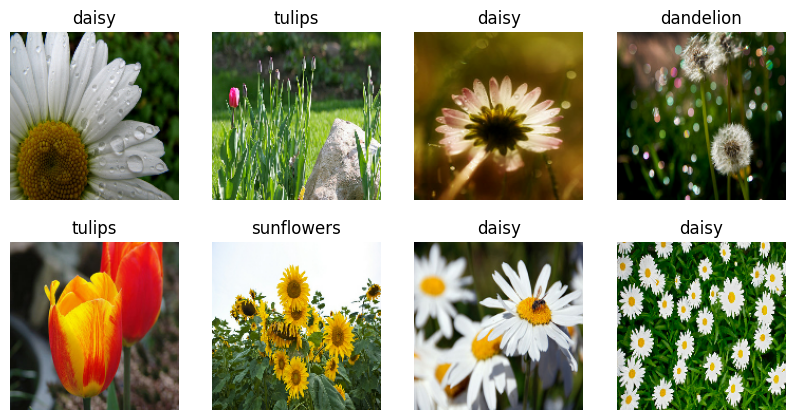

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 62ms/step - accuracy: 0.4254 - loss: 1.3094 - val_accuracy: 0.5817 - val_loss: 1.0432
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 75ms/step - accuracy: 0.5984 - loss: 1.0177 - val_accuracy: 0.6417 - val_loss: 0.9340
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 123ms/step - accuracy: 0.6390 - loss: 0.9091 - val_accuracy: 0.6703 - val_loss: 0.8830
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - accuracy: 0.6815 - loss: 0.8247 - val_accuracy: 0.6403 - val_loss: 0.9580
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 61ms/step - accuracy: 0.6999 - loss: 0.7776 - val_accuracy: 0.6662 - val_loss: 0.9033
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - accuracy: 0.6672 - loss: 0.9177 - val_accuracy: 0.8106 - val_loss: 0.5672
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.8348 - loss: 0.4726 - val_accuracy: 0.8338 - val_loss: 0.4530
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.

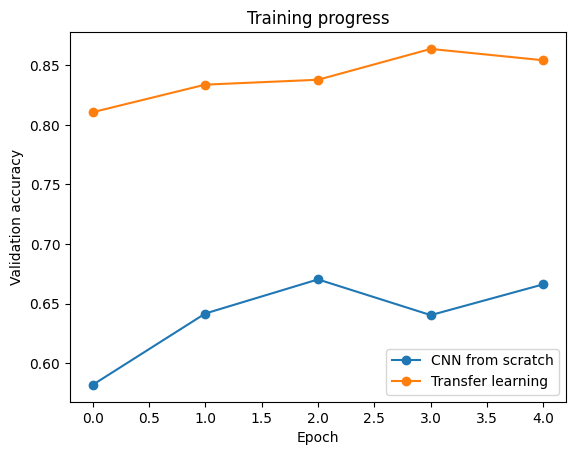

              precision    recall  f1-score   support

       daisy       0.83      0.90      0.86       107
   dandelion       0.88      0.92      0.90       191
       roses       0.77      0.87      0.82       119
  sunflowers       0.83      0.89      0.86       135
      tulips       0.94      0.73      0.82       182

    accuracy                           0.85       734
   macro avg       0.85      0.86      0.85       734
weighted avg       0.86      0.85      0.85       734



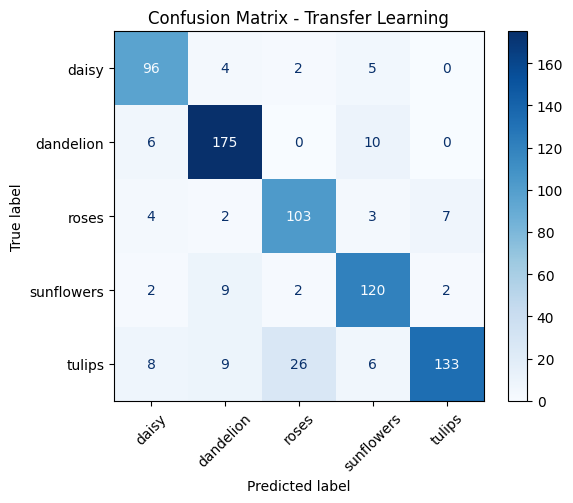

In [1]:
# Flower Classification: Transfer Learning (MobileNetV2) vs CNN from scratch
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# 1. Download the flower photos dataset (5 types of flowers)
url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
root = pathlib.Path(keras.utils.get_file("flower_photos", origin=url, untar=True))
data_dir = next(p for p in [root, root / "flower_photos", root.parent / "flower_photos"]
                if p.is_dir() and list(p.glob("*/*.jpg")))
print("Total photos:", len(list(data_dir.glob("*/*.jpg"))))

# 2. Load as training (80%) and validation (20%) sets
IMG = (160, 160)
train_ds = keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="training", seed=42,
    image_size=IMG, batch_size=32)
val_ds = keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="validation", seed=42,
    image_size=IMG, batch_size=32)
class_names = train_ds.class_names
print("Classes:", class_names)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

# 3. Look at some photos
plt.figure(figsize=(10, 5))
for images, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

# 4. Data augmentation (random flips, rotations, zooms give the model more variety)
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])
loss = keras.losses.SparseCategoricalCrossentropy(from_logits=True)

# 5. Model 1: small CNN trained from scratch
cnn = keras.Sequential([
    layers.Input(shape=IMG + (3,)),
    augment,
    layers.Rescaling(1.0 / 255),
    layers.Conv2D(16, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(class_names)),
])
cnn.compile(optimizer="adam", loss=loss, metrics=["accuracy"])
h_cnn = cnn.fit(train_ds, validation_data=val_ds, epochs=5)

# 6. Model 2: transfer learning with MobileNetV2 (pre-trained on ImageNet)
base = keras.applications.MobileNetV2(input_shape=IMG + (3,), include_top=False, weights="imagenet")
base.trainable = False   # keep what it already learned

inputs = keras.Input(shape=IMG + (3,))
x = augment(inputs)
x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(class_names))(x)
tl = keras.Model(inputs, outputs)
tl.compile(optimizer="adam", loss=loss, metrics=["accuracy"])
h_tl = tl.fit(train_ds, validation_data=val_ds, epochs=5)

# 7. Compare
cnn_acc = cnn.evaluate(val_ds, verbose=0)[1]
tl_acc = tl.evaluate(val_ds, verbose=0)[1]
print("CNN from scratch validation accuracy:", round(cnn_acc, 3))
print("Transfer learning validation accuracy:", round(tl_acc, 3))

plt.plot(h_cnn.history["val_accuracy"], marker="o", label="CNN from scratch")
plt.plot(h_tl.history["val_accuracy"], marker="o", label="Transfer learning")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Training progress")
plt.legend()
plt.show()

# 8. Detailed results for the transfer learning model
y_true, y_pred = [], []
for images, labels in val_ds:
    y_true.extend(labels.numpy())
    y_pred.extend(tl.predict(images, verbose=0).argmax(axis=1))
print(classification_report(y_true, y_pred, target_names=class_names))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                       display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix - Transfer Learning")
plt.show()

In [2]:
import tensorflow as tf
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
